<a href="https://colab.research.google.com/github/Luckysolex/msc-research-ai-prototype/blob/main/notebooks/On_Device_Malaria_Cell_Classifier_on_the_XIAO_ESP32_S3_Sense.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step1 - Loading Dataset

In [1]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/archive.zip'
extract_path = '/content/cell_images'

# List all files in MyDrive to help find the correct path if it fails
mydrive_path = '/content/drive/MyDrive'
if os.path.exists(mydrive_path):
    print("Files in MyDrive:", os.listdir(mydrive_path))
else:
    print("Google Drive is not mounted or not accessible yet.")

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("\nDone. Contents:")
    print(os.listdir(extract_path))
else:
    print(f"\nError: The file {zip_path} still could not be found. Please check the list above for the correct filename.")

Files in MyDrive: ['Saved from Chrome', 'Colab Notebooks', 'calculator.py', 'FIle handling Numpy arrays.ipynb', 'car_prices.csv', '.ipynb_checkpoints', 'StudentsPerformance.csv', 'Pandas_data_analysis_assessment.ipynb', 'housing.csv', 'GitHub revamb.gdoc', 'EAI 806 Assignment (1).gdoc', 'Cassava_Processing_Automation.gdoc', 'AirPassengers.csv', 'Mall_Customers.csv', 'Assignment_CustomerSegmentationwithK_Means.ipynb', 'Strategic Case Analysis: Micoderm.gdoc', 'AI Study Timetable Creation.gsheet', 'EAI 806 Assignment.gdoc', 'EAI 807 - Group 12 Fieldwork Report.gdoc', 'EAI 807 - Group 12 Fieldwork Report.docx', 'AYF Prayer session.gdoc', 'EAI 804 Mathematical Methods.pptx', 'EAI 803.pptx', 'Assignment.docx', 'LectureGuide EAI 802.docx', 'TS certificate.pdf', 'EAI 807 21-01-2026 2.pdf', 'EAI 807 _Entreprenuership Chapters 1_4.pdf', 'EAI 807 21-01-2026 2.gdoc', 'Chapters 4.pdf', 'EAI 807 _Entreprenuership Chapters 1_4 (1).gdoc', 'ASSIGNMENT EAI 807.docx', 'EAI 807 _Entreprenuership Chapters

In [4]:
# Inspect the nested cell_images directory to locate Parasitized and Uninfected folders
nested_path = '/content/cell_images/cell_images'

if os.path.exists(nested_path):
    print("Contents of nested cell_images directory:", os.listdir(nested_path))

    # Walk through the subdirectories and count files inside them
    for item in os.listdir(nested_path):
        item_path = os.path.join(nested_path, item)
        if os.path.isdir(item_path):
            image_count = len(os.listdir(item_path))
            print(f"Folder '{item}' contains {image_count} files/images")
else:
    print(f"The directory {nested_path} does not exist.")

Contents of nested cell_images directory: ['cell_images', 'Uninfected', 'Parasitized']
Folder 'cell_images' contains 2 files/images
Folder 'Uninfected' contains 13780 files/images
Folder 'Parasitized' contains 13780 files/images


# Step 2 - Preprocessing the data

**Reasoning**:
Define the image directory and the optimal configuration parameters for the resource-constrained ESP32-S3 microcontroller, including target size, batch size, and random seed.



In [5]:
import numpy as np
import random

# 1. Define dataset directory pointing to the correct nested path
DATA_DIR = '/content/cell_images/cell_images'

# 2. Configuration parameters optimized for resource-constrained ESP32-S3 microcontroller
# ESP32-S3 has limited SRAM; 64x64 pixels with 3 channels conserves memory during deployment
IMAGE_SIZE = (64, 64)
BATCH_SIZE = 32
SEED = 42

# Set random seeds for reproducibility
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"Dataset Directory: {DATA_DIR}")
print(f"Target Image Size: {IMAGE_SIZE}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"Random Seed: {SEED}")

Dataset Directory: /content/cell_images/cell_images
Target Image Size: (64, 64)
Batch Size: 32
Random Seed: 42


# Task
Load and preprocess the malaria cell images from "/content/cell_images/cell_images", split the dataset into training, validation, and test sets, and build an ESP32-S3 optimized lightweight CNN model. Then, compile, train, and evaluate the model, and convert it into a fully quantized TensorFlow Lite (TFLite) model and a C source byte array for Arduino IDE deployment on the XIAO ESP32-S3 Sense.

## Define Data Paths and Parameters

### Subtask:
Define data paths and parameters optimized for the ESP32-S3 deployment.


## Load and Split Dataset

### Subtask:
Load images from the dataset directory and split them into Training, Validation, and Test sets using tf.keras.utils.image_dataset_from_directory.


**Reasoning**:
Load and split the dataset from the clean DATA_DIR using tf.keras.utils.image_dataset_from_directory into training, validation, and test datasets according to the required ratios, and print the counts of batches to verify.



**Reasoning**:
We will create a code block to define the rescaling layer, map it over the training, validation, and test datasets, and apply caching and prefetching to optimize I/O performance during training.



In [6]:
import tensorflow as tf

# 1. Load the dataset from DATA_DIR with an 80/20 train/validation split
# We explicitly define the class_names to ignore the nested cell_images folder
train_ds, val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset='both',
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    class_names=['Parasitized', 'Uninfected']
)

# Get class names from the dataset
class_names = train_ds.class_names
print(f"Class names found: {class_names}")

# 2. Further split val_ds_raw into validation and test sets in a 50/50 ratio
val_batches = tf.data.experimental.cardinality(val_ds_raw).numpy()
val_size = val_batches // 2

val_ds = val_ds_raw.take(val_size)
test_ds = val_ds_raw.skip(val_size)

# Print information to verify the dataset sizes
train_batches = tf.data.experimental.cardinality(train_ds).numpy()
val_final_batches = tf.data.experimental.cardinality(val_ds).numpy()
test_final_batches = tf.data.experimental.cardinality(test_ds).numpy()

print(f"\nNumber of training batches: {train_batches} (approx. {train_batches * BATCH_SIZE} images)")
print(f"Number of validation batches: {val_final_batches} (approx. {val_final_batches * BATCH_SIZE} images)")
print(f"Number of test batches: {test_final_batches} (approx. {test_final_batches * BATCH_SIZE} images)")

Found 27558 files belonging to 2 classes.
Using 22047 files for training.
Using 5511 files for validation.
Class names found: ['Parasitized', 'Uninfected']

Number of training batches: 689 (approx. 22048 images)
Number of validation batches: 86 (approx. 2752 images)
Number of test batches: 87 (approx. 2784 images)


In [7]:
import tensorflow as tf

# 1. Define rescaling layer to map pixel values from [0, 255] to [0, 1]
normalization_layer = tf.keras.layers.Rescaling(1./255)

# 2. Apply the rescaling layer to train, validation, and test datasets
train_ds_scaled = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds_scaled = val_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds_scaled = test_ds.map(lambda x, y: (normalization_layer(x), y))

# 3. Configure datasets for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds_optimized = train_ds_scaled.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds_optimized = val_ds_scaled.cache().prefetch(buffer_size=AUTOTUNE)
test_ds_optimized = test_ds_scaled.cache().prefetch(buffer_size=AUTOTUNE)

print("Datasets successfully rescaled, cached, and configured with prefetching.")

Datasets successfully rescaled, cached, and configured with prefetching.


In [8]:
print(train_ds.class_names)

['Parasitized', 'Uninfected']


## Dataset Preprocessing and Optimization

### Subtask:
Rescale image pixels and configure performance optimization (caching/prefetching) for the dataset splits.


## Build an ESP32-Optimized CNN Model

### Subtask:
Design a lightweight, memory-efficient Convolutional Neural Network (CNN) suitable for deployment on the resource-constrained ESP32-S3 microcontroller.


**Reasoning**:
Construct and summarize a lightweight CNN model optimized for the ESP32-S3 microcontroller according to the subtask instructions.



In [9]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Construct a highly compact model optimized for limited memory/SRAM (under ~100k parameters)
model = Sequential([
    Input(shape=(64, 64, 3)),
    Conv2D(8, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(16, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

# Print model summary to verify parameters count
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        65,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,633 (279.82 KB)

 Trainable params: 71,633 (279.82 KB)

 Non-trainable params: 0 (0.00 B)

**Reasoning**:
Compile and train the lightweight CNN model on the optimized datasets, keeping track of the training history for visualization and evaluation.



## Compile and Train the Model

### Subtask:
Compile the lightweight CNN model using appropriate loss, optimizer, and metrics, and train it on the prepared dataset while monitoring validation performance.


In [10]:
# Compile the model with Adam optimizer, binary crossentropy, and accuracy metrics
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train the model for 10 epochs
EPOCHS = 10
history = model.fit(
    train_ds_optimized,
    validation_data=val_ds_optimized,
    epochs=EPOCHS
)

print("Model compilation and training completed successfully.")

Epoch 1/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 72s 81ms/step - accuracy: 0.7938 - loss: 0.4304 - val_accuracy: 0.9419 - val_loss: 0.1755
Epoch 2/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 66s 77ms/step - accuracy: 0.9463 - loss: 0.1866 - val_accuracy: 0.9553 - val_loss: 0.1475
Epoch 3/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 81s 75ms/step - accuracy: 0.9546 - loss: 0.1628 - val_accuracy: 0.9568 - val_loss: 0.1345
Epoch 4/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 54s 78ms/step - accuracy: 0.9555 - loss: 0.1496 - val_accuracy: 0.9571 - val_loss: 0.1286
Epoch 5/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 54s 78ms/step - accuracy: 0.9567 - loss: 0.1408 - val_accuracy: 0.9524 - val_loss: 0.1428
Epoch 6/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 79s 74ms/step - accuracy: 0.9588 - loss: 0.1373 - val_accuracy: 0.9575 - val_loss: 0.1299
Epoch 7/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 82s 74ms/step - accuracy: 0.9592 - loss: 0.1289 - val_accuracy: 0.9578 - val_loss: 0.1270
Epoch 8/10
689/689 ━━━━━━━━━━━━━━━━━━━━ 53s 77ms/step - accuracy: 0.9608 - loss: 0.1239 - 

### Step 4 - Model Evaluation and Performance Curves

87/87 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.9605 - loss: 0.1210

Test Loss: 0.1210
Test Accuracy: 0.9605


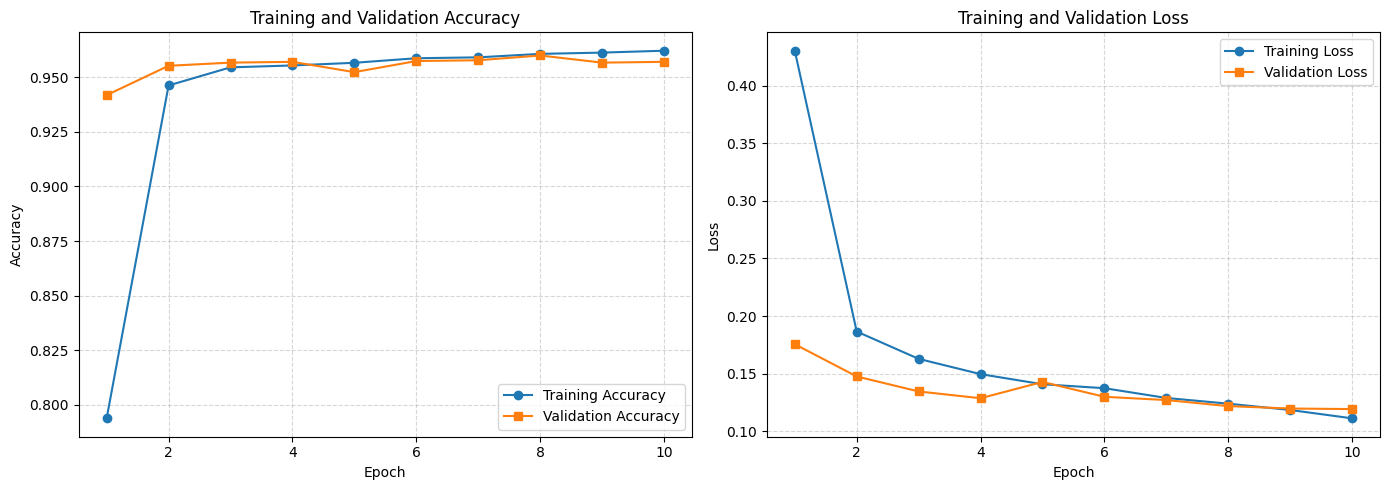

In [11]:
import matplotlib.pyplot as plt

# 1. Evaluate the model on our test dataset
test_loss, test_accuracy = model.evaluate(test_ds_optimized)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# 2. Extract accuracy and loss records from history
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# 3. Plot accuracy and loss curves
plt.figure(figsize=(14, 5))

# Plot Training & Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='s')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)

# Plot Training & Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='s')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Step 5 - Full Integer Post-Training Quantization

To run inference on an ESP32-S3 S3 Sense, converting the standard float32 weights ($1.5$ MB) into 8-bit integers (`int8`) is highly recommended. This step reduces the overall size dramatically to around $70$ KB and leverages the ESP32-S3 Vector Extension instructions for fast calculations.

In [12]:
import os

# 1. Define a representative dataset generator for calibration
def representative_data_gen():
    """
    Calibration dataset generator for INT8 Post-Training Quantization.
    Uses 640 representative training images (20 batches × 32)
    to compute per-tensor scale factors and zero-point offsets.
    A minimum of 200-500 images is recommended for stable calibration.
    """
    for input_value, _ in train_ds_optimized.take(20):
        for i in range(input_value.shape[0]):
            yield [tf.expand_dims(input_value[i], axis=0)]

# 2. Initialize the converter
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data_gen

# Enforce full integer-only quantization (required by TensorFlow Lite Micro target operations)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# 3. Convert the model
tflite_quant_model = converter.convert()

# 4. Save the quantized model
tflite_model_path = 'malaria_quant_model.tflite'
with open(tflite_model_path, 'wb') as f:
    f.write(tflite_quant_model)

# 5. Measure model footprint
original_size = os.path.getsize(tflite_model_path) / 1024
print(f"Quantized TFLite Model Size: {original_size:.2f} KB")

Saved artifact at '/tmp/tmp1w_hrse6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  135304803246992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135304803248336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135304803247760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135304803248528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135304803246800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135304803248720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135304803247376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135304803249296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135304803243152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135304803249488: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Quantized TFLite Model Size: 77.91 KB


In [13]:
import tensorflow as tf

# Instantiate and allocate tensors for the interpreter
model_path = "malaria_quant_model.tflite"
interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

print("Class names:", train_ds.class_names)
print("Model input:", interpreter.get_input_details()[0])
print("Model output:", interpreter.get_output_details()[0])

Class names: ['Parasitized', 'Uninfected']
Model input: {'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([ 1, 64, 64,  3], dtype=int32), 'shape_signature': array([-1, 64, 64,  3], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.0038487303536385298, -128), 'quantization_parameters': {'scales': array([0.00384873], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}
Model output: {'name': 'StatefulPartitionedCall_1:0', 'index': 26, 'shape': array([1, 1], dtype=int32), 'shape_signature': array([-1,  1], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.00390625, -128), 'quantization_parameters': {'scales': array([0.00390625], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


### Step 6 - Convert Model to a C Array Header File (`.h`)

We convert the `.tflite` model into a C array so it can be directly embedded in the flash memory of your microcontroller.

In [14]:

!apt-get update -qq && apt-get install -y -qq xxd

# Convert the TFLite model to a C header
!xxd -i malaria_quant_model.tflite > malaria_model.h

# Inspect model metadata
import tensorflow as tf

model_path = "malaria_quant_model.tflite"
interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

print("HEADER GENERATED")
!head -n 8 malaria_model.h

print("\nMODEL INPUTS")
for tensor in interpreter.get_input_details():
    print("Name:", tensor["name"])
    print("Shape:", tensor["shape"])
    print("Data type:", tensor["dtype"])
    print("Quantization:", tensor["quantization"])
    print("Quantization parameters:", tensor["quantization_parameters"])

print("\nMODEL OUTPUTS")
for tensor in interpreter.get_output_details():
    print("Name:", tensor["name"])
    print("Shape:", tensor["shape"])
    print("Data type:", tensor["dtype"])
    print("Quantization:", tensor["quantization"])
    print("Quantization parameters:", tensor["quantization_parameters"])

print("\nMODEL OPERATORS")
tf.lite.experimental.Analyzer.analyze(model_path=model_path)


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package xxd.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../xxd_2%3a9.1.0016-1ubuntu7.20_amd64.deb ...
Unpacking xxd (2:9.1.0016-1ubuntu7.20) ...
Setting up xxd (2:9.1.0016-1ubuntu7.20) ...
Processing triggers for man-db (2.12.0-4build2) ...
HEADER GENERATED
unsigned char malaria_quant_model_tflite[] = {
  0x1c, 0x00, 0x00, 0x00, 0x54, 0x46, 0x4c, 0x33, 0x14, 0x00, 0x20, 0x00,
  0x1c, 0x00, 0x18, 0x00, 0x14, 0x00, 0x10, 0x00, 0x0c, 0x00, 0x00, 0x00,
  0x08, 0x00, 0x04, 0x00, 0x14, 0x00, 0x00, 0x00, 0x1c, 0x00, 0x00, 0x00,
  0x8c, 0x00, 0x00, 0x00, 0xe4, 0x00, 0x00, 0x00, 0xa4, 0x1b, 0x01, 0x00,
  0xb4, 0x1b, 0x01, 0x00, 0xc8, 0x36, 0x01, 0x00, 0x03, 0x00, 0x00, 0x00,
  0x01, 0x00, 0x00, 0x00, 0x04, 0x00, 0x00, 0x00, 0x5

**Reasoning**:
Create the fully functional Arduino sketch (malaria_detection.ino) incorporating the TensorFlow Lite Micro library, the quantized C-byte array model, setting the appropriate tensor arena size, registering the required ops, and running mock inference inside loop().



### Arduino Sketch (`malaria_detection.ino`)

This sketch loads the quantized TFLite model from the C header file (`malaria_model.h`), sets up the required operations on a 50 KB tensor arena optimized for the ESP32-S3's SRAM, and runs continuous mock inferences to verify execution.

In [15]:
import textwrap
from pathlib import Path

# Define the output file path
OUTPUT_FILE = Path("malaria_detection.ino")

arduino_sketch = """/*
* On-Device Malaria Cell Classifier
* Hardware: Seeed Studio XIAO ESP32-S3 Sense
* Framework: EloquentTinyML
* Author: Lucky Ayinwugyefun Solomon
* MSc Embedded AI — University of Abuja (Erasmus+ Co-funded)
* Hardware support: Seeed Studio, Shenzhen
*
* Description:
* Loads a fully INT8-quantized CNN trained on the NIH Malaria Cell
* Image Dataset. Classifies cells as Parasitized or Uninfected.
* Current stage: prototype with synthetic input.
* Next phase: replace mock_input with live OV2640 camera frame data.
*/

#include <Arduino.h>
#include <math.h>
#include "esp_camera.h"
#include "esp_heap_caps.h"
#include "TensorFlowLite_ESP32.h"

#include "tensorflow/lite/micro/all_ops_resolver.h"
#include "tensorflow/lite/micro/micro_error_reporter.h"
#include "tensorflow/lite/micro/micro_interpreter.h"
#include "tensorflow/lite/schema/schema_generated.h"

#include "malaria_model.h"

// XIAO ESP32-S3 Sense camera pins (ESP32 Arduino core 2.x camera API).
#define PWDN_GPIO_NUM     -1
#define RESET_GPIO_NUM   -1
#define XCLK_GPIO_NUM     10
#define SIOD_GPIO_NUM     40
#define SIOC_GPIO_NUM     39
#define Y9_GPIO_NUM       48
#define Y8_GPIO_NUM       11
#define Y7_GPIO_NUM       12
#define Y6_GPIO_NUM       14
#define Y5_GPIO_NUM       16
#define Y4_GPIO_NUM       18
#define Y3_GPIO_NUM       17
#define Y2_GPIO_NUM       15
#define VSYNC_GPIO_NUM    38
#define HREF_GPIO_NUM     47
#define PCLK_GPIO_NUM     13

constexpr int MODEL_WIDTH = 64;
constexpr int MODEL_HEIGHT = 64;
constexpr int MODEL_CHANNELS = 3;
constexpr size_t TENSOR_ARENA_SIZE = 160 * 1024;

// The generated xxd header is expected to define:
//   unsigned char malaria_quant_model_tflite[]
//   unsigned int malaria_quant_model_tflite_len
// If your header uses different names, change these two identifiers below.
const unsigned char *g_model_data = malaria_quant_model_tflite;
const size_t g_model_length = malaria_quant_model_tflite_len;

uint8_t *tensor_arena = nullptr;
tflite::MicroErrorReporter micro_error_reporter;
tflite::ErrorReporter *error_reporter = &micro_error_reporter;
const tflite::Model *model = nullptr;
tflite::AllOpsResolver resolver;
tflite::MicroInterpreter *interpreter = nullptr;
TfLiteTensor *input = nullptr;
TfLiteTensor *output = nullptr;

bool cameraReady = false;

static int clampInt(int value, int low, int high) {
  if (value < low) return low;
  if (value > high) return high;
  return value;
}

static int8_t quantizePixel(uint8_t pixel, float scale, int zero_point) {
  // Training preprocessing: Rescaling(1./255), producing [0, 1] pixels.
  const float normalized = static_cast<float>(pixel) / 255.0f;
  int32_t quantized = static_cast<int32_t>(roundf(normalized / scale)) + zero_point;
  quantized = clampInt(quantized, -128, 127);
  return static_cast<int8_t>(quantized);
}

// Convert an RGB565 camera frame to the model's NHWC RGB int8 input.
// Center-crops the largest square, then nearest-neighbor resizes to 64x64.
static bool preprocessFrame(const camera_fb_t *fb) {
  if (!fb || !fb->buf || !input) return false;
  if (fb->format != PIXFORMAT_RGB565) {
    Serial.println("ERROR: Camera framebuffer is not RGB565.");
    return false;
  }

  const int source_width = fb->width;
  const int source_height = fb->height;
  const int crop_size = (source_width < source_height) ? source_width : source_height;
  const int crop_x = (source_width - crop_size) / 2;
  const int crop_y = (source_height - crop_size) / 2;

  const float scale = input->params.scale;
  const int zero_point = input->params.zero_point;
  if (scale <= 0.0f) {
    Serial.println("ERROR: Invalid input quantization scale.");
    return false;
  }

  int index = 0;
  for (int y = 0; y < MODEL_HEIGHT; ++y) {
    const int sy = crop_y + (y * crop_size) / MODEL_HEIGHT;
    for (int x = 0; x < MODEL_WIDTH; ++x) {
      const int sx = crop_x + (x * crop_size) / MODEL_WIDTH;
      const size_t pixel_index = static_cast<size_t>(sy) * source_width + sx;
      const uint16_t pixel = reinterpret_cast<const uint16_t *>(fb->buf)[pixel_index];

      // RGB565 channel extraction. This assumes the framebuffer's uint16_t
      // values are native-endian RGB565, as commonly returned by esp32-camera.
      const uint8_t r5 = (pixel >> 11) & 0x1F;
      const uint8_t g6 = (pixel >> 5) & 0x3F;
      const uint8_t b5 = pixel & 0x1F;
      const uint8_t red   = (r5 * 255 + 15) / 31;
      const uint8_t green = (g6 * 255 + 31) / 63;
      const uint8_t blue  = (b5 * 255 + 15) / 31;

      input->data.int8[index++] = quantizePixel(red, scale, zero_point);
      input->data.int8[index++] = quantizePixel(green, scale, zero_point);
      input->data.int8[index++] = quantizePixel(blue, scale, zero_point);
    }
  }
  return true;
}

static bool initializeCamera() {
  camera_config_t config;
  config.ledc_channel = LEDC_CHANNEL_0;
  config.ledc_timer = LEDC_TIMER_0;
  config.pin_d0 = Y2_GPIO_NUM;
  config.pin_d1 = Y3_GPIO_NUM;
  config.pin_d2 = Y4_GPIO_NUM;
  config.pin_d3 = Y5_GPIO_NUM;
  config.pin_d4 = Y6_GPIO_NUM;
  config.pin_d5 = Y7_GPIO_NUM;
  config.pin_d6 = Y8_GPIO_NUM;
  config.pin_d7 = Y9_GPIO_NUM;
  config.pin_xclk = XCLK_GPIO_NUM;
  config.pin_pclk = PCLK_GPIO_NUM;
  config.pin_vsync = VSYNC_GPIO_NUM;
  config.pin_href = HREF_GPIO_NUM;
  config.pin_sscb_sda = SIOD_GPIO_NUM;
  config.pin_sscb_scl = SIOC_GPIO_NUM;
  config.pin_pwdn = PWDN_GPIO_NUM;
  config.pin_reset = RESET_GPIO_NUM;
  config.xclk_freq_hz = 20000000;
  config.pixel_format = PIXFORMAT_RGB565;
  config.frame_size = FRAMESIZE_QQVGA;  // 160x120
  config.jpeg_quality = 12;
  config.fb_count = 1;
  config.fb_location = CAMERA_FB_IN_PSRAM;
  config.grab_mode = CAMERA_GRAB_WHEN_EMPTY;

  const esp_err_t err = esp_camera_init(&config);
  if (err != ESP_OK) {
    Serial.printf("Camera init failed: 0x%x\n", err);
    return false;
  }

  sensor_t *sensor = esp_camera_sensor_get();
  if (sensor) {
    // Keep sensor defaults unless the user has calibrated image orientation.
    sensor->set_framesize(sensor, FRAMESIZE_QQVGA);
  }
  return true;
}

static bool initializeModel() {
  if (!psramFound()) {
    Serial.println("ERROR: PSRAM not detected. Enable OPI PSRAM in Tools.");
    return false;
  }

  tensor_arena = static_cast<uint8_t *>(
      heap_caps_malloc(TENSOR_ARENA_SIZE, MALLOC_CAP_SPIRAM | MALLOC_CAP_8BIT));
  if (!tensor_arena) {
    Serial.println("ERROR: Could not allocate tensor arena in PSRAM.");
    return false;
  }

  model = tflite::GetModel(g_model_data);
  if (!model) {
    Serial.println("ERROR: Could not read TFLite model.");
    return false;
  }
  if (model->version() != TFLITE_SCHEMA_VERSION) {
    Serial.printf("ERROR: Model schema %d does not match runtime schema %d.\n",
                  model->version(), TFLITE_SCHEMA_VERSION);
    return false;
  }

  // The 5-argument constructor is used by many TensorFlow Lite Micro releases.
  interpreter = new (std::nothrow) tflite::MicroInterpreter(
      model, resolver, tensor_arena, TENSOR_ARENA_SIZE, error_reporter);
  if (!interpreter) {
    Serial.println("ERROR: Could not create MicroInterpreter.");
    return false;
  }

  if (interpreter->AllocateTensors() != kTfLiteOk) {
    Serial.println("ERROR: AllocateTensors failed. Tensor arena may be too small.");
    return false;
  }

  input = interpreter->input(0);
  output = interpreter->output(0);
  if (!input || !output) {
    Serial.println("ERROR: Model input or output tensor is missing.");
    return false;
  }

  if (input->type != kTfLiteInt8 || output->type != kTfLiteInt8) {
    Serial.println("ERROR: Expected int8 input and output tensors.");
    return false;
  }

  if (input->dims->size != 4 ||
      input->dims->data[1] != MODEL_HEIGHT ||
      input->dims->data[2] != MODEL_WIDTH ||
      input->dims->data[3] != MODEL_CHANNELS) {
    Serial.println("ERROR: Model input is not [1,64,64,3].");
    return false;
  }

  Serial.printf("Model loaded: %u bytes\n", static_cast<unsigned>(g_model_length));
  Serial.printf("Input quantization: scale=%.8f zero_point=%d\n",
                input->params.scale, input->params.zero_point);
  Serial.printf("Output quantization: scale=%.8f zero_point=%d\n",
                output->params.scale, output->params.zero_point);
  return true;
}

static void runInference() {
  camera_fb_t *fb = esp_camera_fb_get();
  if (!fb) {
    Serial.println("ERROR: Camera capture failed.");
    return;
  }

  const bool preprocessed = preprocessFrame(fb);
  esp_camera_fb_return(fb);

  if (!preprocessed) {
    Serial.println("ERROR: Frame preprocessing failed.");
    return;
  }

  const uint32_t start_ms = millis();
  if (interpreter->Invoke() != kTfLiteOk) {
    Serial.println("ERROR: Model inference failed.");
    return;
  }
  const uint32_t elapsed_ms = millis() - start_ms;

  const float score =
      (static_cast<int>(output->data.int8[0]) - output->params.zero_point) *
      output->params.scale;

  // Verified training convention: class 0 = Parasitized, class 1 = Uninfected.
  // With sigmoid output representing class 1, >= 0.5 means Uninfected.
  const char *label = (score >= 0.5f) ? "Uninfected" : "Parasitized";

  Serial.println("--------------------------------");
  Serial.printf("Prediction: %s\n", label);
  Serial.printf("Class-1 (Uninfected) score: %.4f\n", score);
  Serial.printf("Inference time: %lu ms\n", static_cast<unsigned long>(elapsed_ms));
  Serial.println("Research prototype only; not for clinical diagnosis.");
}

void setup() {
  Serial.begin(115200);
  delay(1500);
  Serial.println();
  Serial.println("XIAO ESP32-S3 Sense - Malaria Image Classifier");

  if (!initializeModel()) {
    Serial.println("Model initialization failed. Halting.");
    while (true) delay(1000);
  }

  cameraReady = initializeCamera();
  if (!cameraReady) {
    Serial.println("Camera initialization failed. Check board and pin configuration.");
    while (true) delay(1000);
  }

  Serial.println("Ready. Capturing and classifying frames...");
}

void loop() {
  if (cameraReady) {
    runInference();
  }
  delay(1000);
}
"""

def main():
    OUTPUT_FILE.write_text(textwrap.dedent(arduino_sketch).lstrip(), encoding="utf-8")
    print(f"Generated: {OUTPUT_FILE.resolve()}")
    print("Copy this .ino and malaria_model.h into the same Arduino sketch folder.")
    print("Check the generated header symbols match malaria_quant_model_tflite and malaria_quant_model_tflite_len.")
    print("This generator targets ESP32 Arduino core 2.x camera config field names pin_sscb_sda/pin_sscb_scl.")

if __name__ == "__main__":
    main()

Generated: /content/malaria_detection.ino
Copy this .ino and malaria_model.h into the same Arduino sketch folder.
Check the generated header symbols match malaria_quant_model_tflite and malaria_quant_model_tflite_len.
This generator targets ESP32 Arduino core 2.x camera config field names pin_sscb_sda/pin_sscb_scl.


## Test

In [22]:
from google.colab import files

uploaded = files.upload()

Saving parasitized_test.png to parasitized_test.png
Saving uninfected_test.png to uninfected_test.png


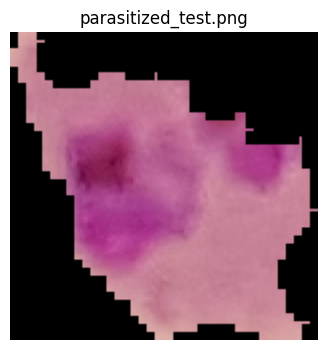

Image: parasitized_test.png
Original dimensions: (115, 115)


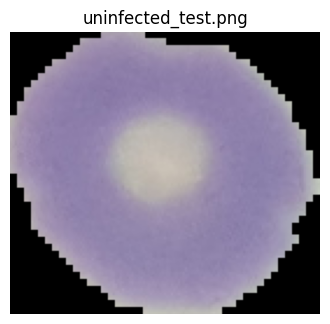

Image: uninfected_test.png
Original dimensions: (133, 121)


In [23]:
from PIL import Image
import matplotlib.pyplot as plt

image_names = [
    "parasitized_test.png",
    "uninfected_test.png"
]

for name in image_names:
    img = Image.open(name).convert("RGB")

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(name)
    plt.axis("off")
    plt.show()

    print("Image:", name)
    print("Original dimensions:", img.size)

In [24]:

import tensorflow as tf
import numpy as np

# Load the quantized model
interpreter = tf.lite.Interpreter(
    model_path="/content/malaria_quant_model.tflite"
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Display model input/output information
print("INPUT DETAILS:")
print(input_details)

print("\nOUTPUT DETAILS:")
print(output_details)

INPUT DETAILS:
[{'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([ 1, 64, 64,  3], dtype=int32), 'shape_signature': array([-1, 64, 64,  3], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.0038487303536385298, -128), 'quantization_parameters': {'scales': array([0.00384873], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

OUTPUT DETAILS:
[{'name': 'StatefulPartitionedCall_1:0', 'index': 26, 'shape': array([1, 1], dtype=int32), 'shape_signature': array([-1,  1], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.00390625, -128), 'quantization_parameters': {'scales': array([0.00390625], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]


In [25]:

from PIL import Image
import numpy as np
import tensorflow as tf

# Your two known images
test_images = {
    "parasitized_test.png": "Parasitized",
    "uninfected_test.png": "Uninfected"
}

# Get model input/output quantization parameters
input_scale, input_zero = input_details[0]["quantization"]
output_scale, output_zero = output_details[0]["quantization"]

for filename, expected_label in test_images.items():

    # Load image and convert to RGB
    image = Image.open(filename).convert("RGB")

    # Resize to the model's expected dimensions.
    # Bilinear interpolation matches the training pipeline default.
    image = image.resize((64, 64), Image.Resampling.BILINEAR)

    # Convert pixels to NumPy array
    image_array = np.asarray(image, dtype=np.float32)

    # Normalize pixels from [0,255] to [0,1]
    image_array = image_array / 255.0

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Quantize input for INT8 model
    quantized_input = np.round(
        image_array / input_scale + input_zero
    )

    quantized_input = np.clip(
        quantized_input, -128, 127
    ).astype(np.int8)

    # Run inference
    interpreter.set_tensor(
        input_details[0]["index"],
        quantized_input
    )

    interpreter.invoke()

    # Get raw model output
    raw_output = interpreter.get_tensor(
        output_details[0]["index"]
    )

    # Convert output back to probability
    score = (
        raw_output.astype(np.float32) - output_zero
    ) * output_scale

    uninfected_score = float(score.flatten()[0])

    # Interpret prediction
    if uninfected_score >= 0.5:
        prediction = "Uninfected"
    else:
        prediction = "Parasitized"

    print("\n--------------------------------")
    print("Image:", filename)
    print("Expected:", expected_label)
    print("Predicted:", prediction)
    print("Uninfected score:", round(uninfected_score, 4))
    print("Parasitized score:", round(1.0 - uninfected_score, 4))
    print("Correct:", prediction == expected_label)
    print("--------------------------------")


--------------------------------
Image: parasitized_test.png
Expected: Parasitized
Predicted: Parasitized
Uninfected score: 0.0
Parasitized score: 1.0
Correct: True
--------------------------------

--------------------------------
Image: uninfected_test.png
Expected: Uninfected
Predicted: Uninfected
Uninfected score: 0.9922
Parasitized score: 0.0078
Correct: True
--------------------------------


In [26]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

true_labels = []
predicted_labels = []

for images, labels in test_ds_optimized:
    images = images.numpy()

    # Quantize the normalized images
    quantized_images = np.round(
        images / input_scale + input_zero
    )
    quantized_images = np.clip(
        quantized_images, -128, 127
    ).astype(np.int8)

    # Run inference for each image
    for i in range(len(quantized_images)):
        interpreter.set_tensor(
            input_details[0]["index"],
            quantized_images[i:i+1]
        )

        interpreter.invoke()

        raw_output = interpreter.get_tensor(
            output_details[0]["index"]
        )

        score = (
            raw_output.astype(np.float32) - output_zero
        ) * output_scale

        uninfected_score = float(score.flatten()[0])

        prediction = 1 if uninfected_score >= 0.5 else 0

        predicted_labels.append(prediction)
        true_labels.append(int(labels.numpy()[i][0]))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    true_labels,
    predicted_labels,
    target_names=["Parasitized", "Uninfected"]
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(true_labels, predicted_labels))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Parasitized       0.97      0.95      0.96      1385
  Uninfected       0.95      0.97      0.96      1374

    accuracy                           0.96      2759
   macro avg       0.96      0.96      0.96      2759
weighted avg       0.96      0.96      0.96      2759


CONFUSION MATRIX
[[1315   70]
 [  37 1337]]
